In [1]:
import os

path = "C:\\Users\\Lenovo\\Downloads\\"
myfile = "web_access.log"


In [2]:
# 1. Reads first 100 characters using read mode

print(os.path.join(path, myfile))

with open(os.path.join(path, myfile), "r") as f:
    content = f.read()
    print(content[:100])


C:\Users\Lenovo\Downloads\web_access.log
192.168.1.10 - - [22/Oct/2026:09:15:22 +0000] "GET /index.html HTTP/1.1" 200 2450
203.0.113.24 - - [


In [3]:
##2.Reads first line content using read mode

with open(os.path.join(path,myfile)) as f:
    for each in f:
        print(each)
        break 


192.168.1.10 - - [22/Oct/2026:09:15:22 +0000] "GET /index.html HTTP/1.1" 200 2450



In [4]:
# 3. Create a list from the log file

with open(os.path.join(path, myfile)) as f:
    for each_line in f:
        print(each_line.split(" "))
        break


['192.168.1.10', '-', '-', '[22/Oct/2026:09:15:22', '+0000]', '"GET', '/index.html', 'HTTP/1.1"', '200', '2450\n']


In [5]:
# 4. Pick IP address and status code from the log file

with open(os.path.join(path, myfile)) as f:
    for each_line in f:
        mylist = each_line.split(" ")

        # Store the IP and status code in variables
        ip, http_status = mylist[0], mylist[8]

        print(http_status)
        print(ip)
        break


200
192.168.1.10


In [6]:
# 5. Store IP addresses and HTTP status codes in lists

ip = []
http_status = []

with open(os.path.join(path, myfile)) as f:
    for each_line in f:
        mylist = each_line.split(" ")

        ip.append(mylist[0])
        http_status.append(mylist[8])

print(ip)
print(http_status)



['192.168.1.10', '203.0.113.24', '198.51.100.17', '192.168.1.10', '203.0.113.24', '198.51.100.17', '192.168.1.22', '203.0.113.24', '198.51.100.17', '192.168.1.10', '192.168.1.22', '203.0.113.24', '198.51.100.17', '192.168.1.10', '203.0.113.24', '192.168.1.22', '198.51.100.17', '192.168.1.10', '203.0.113.24', '192.168.1.22']
['200', '200', '200', '302', '200', '404', '200', '200', '401', '200', '500', '404', '200', '204', '503', '200', '201', '403', '200', '304']


In [7]:
# 6. Count frequency for IP and HTTP status

def frequency(mylist):
    mydict = {}

    for each in mylist:
        if each not in mydict:
            mydict[each] = 1
        else:
            mydict[each] += 1

    return mydict


rest1 = frequency(ip)
rest2 = frequency(http_status)

print("IP Frequency:", rest1)
print("HTTP Status Frequency:", rest2)




IP Frequency: {'192.168.1.10': 5, '203.0.113.24': 6, '198.51.100.17': 5, '192.168.1.22': 4}
HTTP Status Frequency: {'200': 10, '302': 1, '404': 2, '401': 1, '500': 1, '204': 1, '503': 1, '201': 1, '403': 1, '304': 1}


In [8]:
# 7. Save frequency data in CSV files

import csv

def write_to_csv(mydict, filename, column_name):
    with open(os.path.join(path, filename), "w", newline="") as f:
        writer = csv.writer(f)

        writer.writerow(["Sno", column_name, "Frequency"])

        for sno, (item, count) in enumerate(mydict.items(), start=1):
            writer.writerow([sno, item, count])


rest1 = frequency(ip)
rest2 = frequency(http_status)

print("IP frequency:", rest1)
print("HTTP status frequency:", rest2)

write_to_csv(rest1, "ip_frequency.csv", "IP_Address")
write_to_csv(rest2, "http_status_frequency.csv", "HTTP_Status")

print("CSV files created successfully")



IP frequency: {'192.168.1.10': 5, '203.0.113.24': 6, '198.51.100.17': 5, '192.168.1.22': 4}
HTTP status frequency: {'200': 10, '302': 1, '404': 2, '401': 1, '500': 1, '204': 1, '503': 1, '201': 1, '403': 1, '304': 1}
CSV files created successfully


In [9]:
##6.need read and visul data 

import pandas as pd

df = pd.read_csv(r"C:\Users\Lenovo\Downloads\ip_frequency.csv")

print(df)

   Sno     IP_Address  Frequency
0    1   192.168.1.10          5
1    2   203.0.113.24          6
2    3  198.51.100.17          5
3    4   192.168.1.22          4


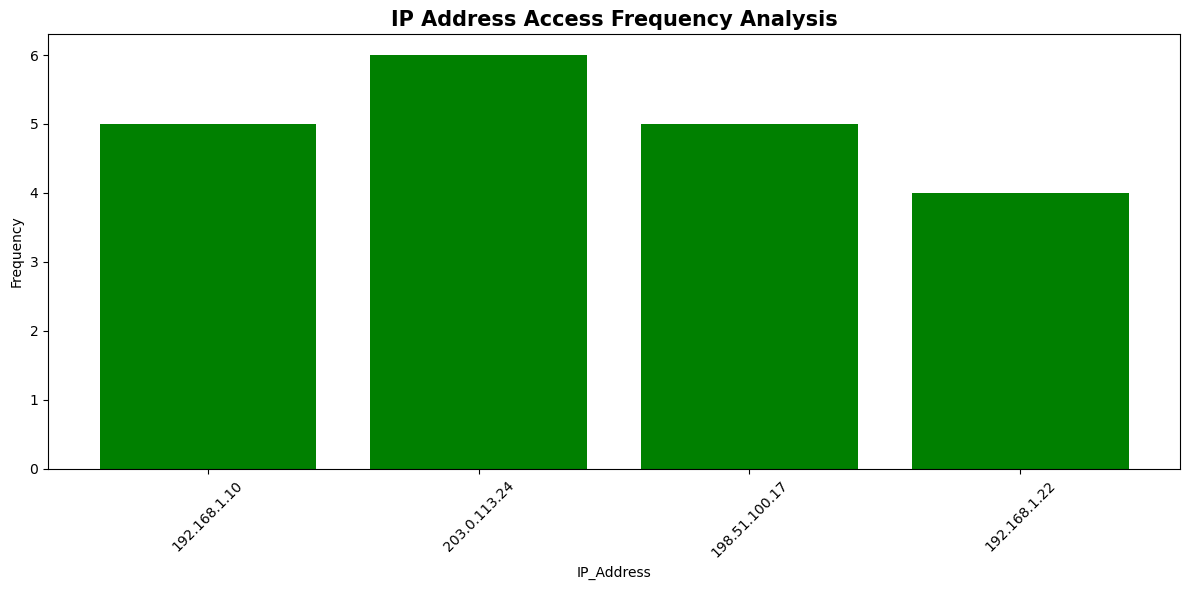

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

plt.bar(df["IP_Address"], df["Frequency"],color="green")
plt.title("IP Address Access Frequency Analysis",fontsize=15,fontweight="bold")
plt.xlabel("IP_Address")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:
import pandas as pd

df = pd.read_csv(r"C:\Users\Lenovo\Downloads\http_status_frequency.csv")

print(df)

   Sno  HTTP_Status  Frequency
0    1          200         10
1    2          302          1
2    3          404          2
3    4          401          1
4    5          500          1
5    6          204          1
6    7          503          1
7    8          201          1
8    9          403          1
9   10          304          1


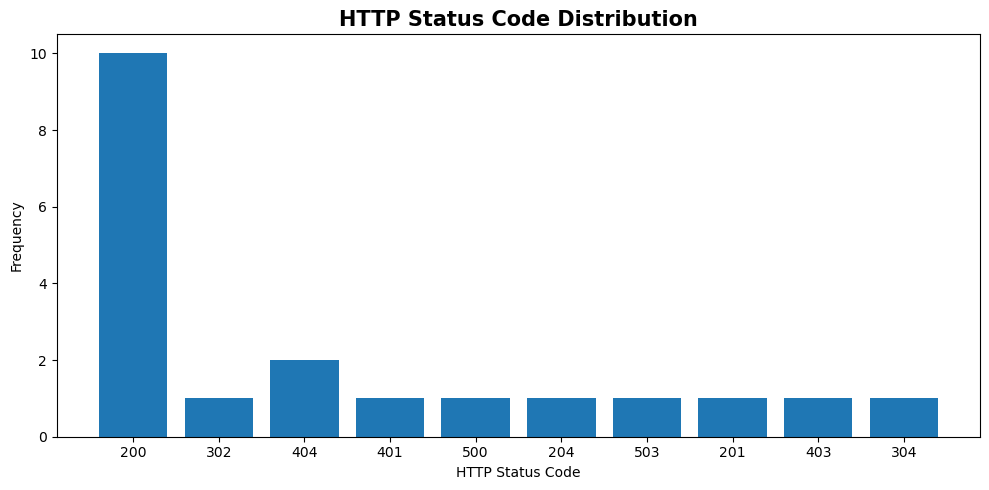

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(df["HTTP_Status"].astype(str), df["Frequency"])

plt.title("HTTP Status Code Distribution",
          fontsize=15, fontweight="bold")
plt.xlabel("HTTP Status Code")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()